# Model Training, Selection, and Evaluation — Ames Housing

**Objective**: Train, compare, and tune regression models on the preprocessed Ames Housing feature matrix, then produce a production-ready serialised model artefact.

**Inputs** (from `02_preprocessing.ipynb`):
- `X_train/val/test.npy` — encoded feature matrices (train 70%, val 15%, test 15%)
- `y_train/val/test.npy` — `log1p`-transformed sale price targets
- `feature_names.json` — column labels for the encoded matrix
- `preprocessor.pkl` — fitted `ColumnTransformer` (used by the serving layer, not this notebook)

**Model progression:**
1. **Linear baseline** — OLS with no regularisation; establishes minimum-viability RMSE
2. **Regularised linear** — Ridge, Lasso, ElasticNet; controls coefficient magnitude and performs implicit feature selection
3. **Tree-based ensembles** — RandomForest, XGBoost; capture non-linear and interaction effects
4. **Cross-validated comparison** — robust ranking across 5 folds before committing to hyperparameter search
5. **Hyperparameter tuning** — Grid and Randomised search on the top candidates
6. **Test set evaluation** — single unblinded measurement of the selected model's generalisation
7. **Diagnostics** — feature importance, residual analysis
8. **Serialisation** — final model + metadata written to `models/`

All evaluation is performed in **log space** during training. Dollar-denominated MAE is reported in the summary tables by inverting with `np.expm1`.


## 1. Configuration and Data Loading

`MODEL_CFG` centralises the random seed for every model that accepts `random_state`. A consistent seed across all models is the minimum requirement for a reproducible comparison — without it, two runs with identical hyperparameters can produce different CV scores simply from different bootstrap samples or tree-growth random draws.

The `.npy` arrays loaded here are the direct binary output of `02_preprocessing.ipynb`. They are loaded with `allow_pickle=False` as a safety measure — feature matrices are plain floating-point arrays and should never require pickle deserialisation. If `np.load` raises an error with this flag, it indicates the preprocessing notebook saved something unexpected.

`feature_names` is loaded from JSON rather than derived here. This guarantees that the names in the importance plots correspond exactly to the column order in the encoded arrays — any mismatch between the name list and the array column ordering would silently mislabel feature importances.


In [3]:
# ── Imports ────────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import joblib
import xgboost as xgb
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, root_mean_squared_error, r2_score, mean_absolute_error, mean_absolute_percentage_error
import pathlib
import json, warnings

# ── Config ─────────────────────────────────────────────────────────────────────
MODEL_CFG = {
    "processed_dir": pathlib.Path("../data/processed"),
    "models_dir": pathlib.Path("../models"),
    "random_state": 42,
    "cv_folds": 5
}

# ── Load arrays ────────────────────────────────────────────────────────────────
# YOUR CODE: load X_train, X_val, X_test, y_train, y_val, y_test, feature_names
processed = MODEL_CFG["processed_dir"]
X_train = np.load(processed/"X_train.npy")
X_val = np.load(processed/"X_val.npy")
X_test = np.load(processed/"X_test.npy")
y_train = np.load(processed/"y_train.npy")
y_val = np.load(processed/"y_val.npy")
y_test = np.load(processed/"y_test.npy")
with open(processed / "feature_names.json") as f:
    feature_names = json.load(f)

# ── Sanity check ───────────────────────────────────────────────────────────────
# YOUR CODE: print shapes, assert feature count matches
print(f"X_train: {X_train.shape}")
print(f"X_val: {X_val.shape}")
print(f"X_test: {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_val: {y_val.shape}")
print(f"y_test: {y_test.shape}")
print(f"feature_names: {len(feature_names)}")
assert X_train.shape[1] == len(feature_names), "Feature count mismatch"

X_train: (1020, 263)
X_val: (219, 263)
X_test: (219, 263)
y_train: (1020,)
y_val: (219,)
y_test: (219,)
feature_names: 263


## 2. Evaluation Helper and Results Table

`evaluate()` computes three complementary metrics on a given split:

| Metric | Formula | Interpretation |
|--------|---------|----------------|
| **RMSE** (log scale) | $\sqrt{\frac{1}{n}\sum(\hat{y} - y)^2}$ | Primary optimisation target; penalises large errors quadratically. Computed on the log-transformed target so it is scale-invariant across the price range. |
| **MAE** (dollars) | $\text{mean}\left(\lvert\text{expm1}(\hat{y}) - \text{expm1}(y)\rvert\right)$ | Dollar-denominated absolute error for stakeholder reporting. Computed after `np.expm1` inversion so it is directly interpretable as average prediction error in USD. |
| **R²** | $1 - \frac{SS_{res}}{SS_{tot}}$ | Proportion of price variance explained. Unitless; provides a baseline-relative measure of fit quality. |

**The MAE computation uses `np.expm1` on the model's log-space predictions, not `mae_log * mean_price`.** The latter approximation is inaccurate for skewed distributions — it understates the dollar error for high-priced properties and overstates it for low-priced ones.

`show_results()` accumulates all model metrics into a single `pd.DataFrame` for easy cross-model comparison. The `results` dictionary is updated after each model is evaluated; `show_results()` can be called at any point to see the current leaderboard.


In [ ]:
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

def evaluate(model, X, y_true, split_name="val") -> dict:
    """
    Evaluate a fitted sklearn estimator on (X, y_true).
    Returns a results dict with rmse, mae, r2, mae_dollars.
    """
    y_pred = model.predict(X)
    rmse = root_mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    # Invert log1p on both sides to get MAE in real dollar scale
    mae_dollars = mean_absolute_error(np.expm1(y_true), np.expm1(y_pred))
    results = {
        "split": split_name,
        "rmse": rmse,
        "mae": mae,
        "r2": r2,
        "mae_dollars": mae_dollars
    }
    
    return results


def show_results(results: list[dict]) -> pd.DataFrame:
    """
    Pretty-print a list of evaluate() dicts as a comparison table.
    Columns: model name | RMSE | MAE | R² | MAE ($)
    """
    
    unique_results = []
    seen_models = set()
    for result in results:
        model_name = result.get("model", "Unknown")
        if model_name not in seen_models:
            unique_results.append(result)
            seen_models.add(model_name)
    results = unique_results
    for result in results:
        model_name = result.get("model", "Unknown")
        rmse = result.get("rmse", 0)
        mae = result.get("mae", 0)
        r2 = result.get("r2", 0)
        mae_dollars = result.get("mae_dollars", 0)
        print(f"{model_name: <20} | {rmse: >10.4f} | {mae: >10.4f} | {r2: >10.4f} | {mae_dollars: >10.2f}")
        
        
    results_df = pd.DataFrame(results)
    return results_df


## 3. Linear Regression Baseline

Ordinary least squares (OLS) provides the **minimum viable baseline**. Any model that cannot outperform OLS on this feature set is not adding value — the feature engineering and preprocessing pipeline is already doing most of the work.

**Why OLS first?**
- It has no hyperparameters to tune, so its validation score is a clean signal about the feature space quality
- Its coefficient vector is interpretable: each coefficient is the expected change in `log1p(SalePrice)` per one-unit increase in the (scaled) feature
- Its failure modes are informative: if OLS has high variance (train RMSE << val RMSE), the feature space is too wide or multicollinear, guiding the choice of regularisation strength

**Expected failure mode**: OLS will likely overfit slightly on 263 features — the validation RMSE will be modestly higher than train RMSE. This is the primary motivation for the regularised models in the next section. A large generalisation gap (>0.05 RMSE difference) would indicate severe overfitting and increase the expected benefit from strong L1/L2 regularisation.


In [19]:
from sklearn.linear_model import LinearRegression

#Train a linear regression model
results = []  # accumulate all model results here
lr = LinearRegression()
lr.fit(X_train, y_train)

#Evaluate on validation set
lr_results = evaluate(lr, X_val, y_val, split_name= "Linear Regression")
lr_results["model"] = "Linear Regression"
results.append(lr_results)




## 4. Regularised Linear Models — Ridge, Lasso, ElasticNet

All three models add a regularisation term to the OLS loss function to reduce coefficient magnitude and control overfitting on high-dimensional feature sets.

| Model | Penalty | Primary effect | When to prefer |
|-------|---------|---------------|----------------|
| **Ridge** | $\lambda \sum \beta_j^2$ (L2) | Shrinks all coefficients uniformly; no sparsity | Many correlated features that should all contribute (e.g., area-related columns) |
| **Lasso** | $\lambda \sum \|\beta_j\|$ (L1) | Drives small coefficients to exactly zero; implicit feature selection | Sparse true signal; interpretability is a priority |
| **ElasticNet** | $\alpha \lambda L1 + (1-\alpha)\lambda L2$ | Combines both penalties; sparsity with grouping of correlated features | Many correlated features where some should be zeroed |

`alpha=1.0` (Ridge/Lasso/ElasticNet) is a starting point — these values will be tuned in Section 7. The regularisation parameter `alpha` here is the sklearn convention: higher `alpha` = stronger regularisation. Note that `l1_ratio=0.5` (ElasticNet default) gives equal L1/L2 weighting.

`max_iter=10_000` is required for Lasso and ElasticNet on this feature matrix (263 columns). The coordinate descent solver may not converge in the default 1,000 iterations on high-dimensional inputs, which would produce a `ConvergenceWarning` and return suboptimal coefficients without raising an error.


In [ ]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet

# YOUR CODE: train Ridge, Lasso, ElasticNet; evaluate each; append to results
ridge = Ridge(random_state=MODEL_CFG["random_state"], alpha=10.0)
ridge.fit(X_train, y_train)
ridge_results = evaluate(ridge, X_val, y_val, split_name="Ridge")
ridge_results["model"] = 'Ridge'
results.append(ridge_results)

lasso = Lasso(random_state=MODEL_CFG["random_state"], alpha=0.001, max_iter=10_000)
lasso.fit(X_train, y_train)
lasso_results = evaluate(lasso, X_val, y_val, split_name="Lasso")
lasso_results["model"] = 'Lasso'
results.append(lasso_results)
# Print zero-coefficient count for Lasso
zero_coeff_count = np.sum(lasso.coef_ == 0)
print(f"Lasso zero coefficients: {zero_coeff_count} out of {len(feature_names)}")

elasticnet = ElasticNet(random_state=MODEL_CFG["random_state"], alpha=0.001, l1_ratio=0.5, max_iter=10_000)
elasticnet.fit(X_train, y_train)
elasticnet_results = evaluate(elasticnet, X_val, y_val, split_name="ElasticNet")
elasticnet_results["model"] = 'ElasticNet'
results.append(elasticnet_results)


Lasso zero coefficients: 189 out of 263


/home/tars/Desktop/AI-Engineering/.venv/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.187e-01, tolerance: 1.596e-02
  model = cd_fast.enet_coordinate_descent(


## 5. Tree-Based Ensemble Models — RandomForest and XGBoost

Tree-based models do not require the scaled inputs that linear models need — they partition feature space by threshold comparisons, which are scale-invariant. The `X_train_enc` arrays are used here unchanged; `RobustScaler` makes no difference to split quality in decision trees.

**RandomForest (`n_estimators=300, max_features="sqrt"`):**
- Bagging of 300 independent trees; prediction is the mean of all trees' outputs
- `max_features="sqrt"` (≈16 of 263 features per split) introduces the feature-level randomness that decorrelates the trees and is the primary driver of variance reduction over a single tree
- `n_jobs=-1` parallelises tree fitting across all available CPU cores — critical for 300 trees

**XGBoost (`n_estimators=300, learning_rate=0.05, max_depth=4`):**
- Gradient boosting: each tree corrects the residuals of the ensemble so far
- `learning_rate=0.05` (shrinkage) scales each tree's contribution, requiring more trees to converge but significantly reducing overfitting vs. `learning_rate=1.0`
- `max_depth=4` limits tree complexity; deep trees in a boosted ensemble overfit aggressively on structured tabular data
- `subsample=0.8, colsample_bytree=0.8` are stochastic regularisation: each tree sees 80% of rows and 80% of features, further decorrelating the ensemble
- `verbosity=0` suppresses XGBoost's per-iteration output, which would flood the notebook with 300 lines

These are **starting configurations**, not tuned values. The CV scores in Section 6 will determine whether tree-based models justify the tuning investment in Section 7.


In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# YOUR CODE: train DT, RF, XGBoost; evaluate each; append to results
dt = DecisionTreeRegressor(random_state=MODEL_CFG["random_state"], max_depth=10)
dt.fit(X_train, y_train)
dt_results = evaluate(dt, X_val, y_val, split_name="Decision Tree")
dt_results["model"] = 'Decision Tree'
results.append(dt_results)

rf = RandomForestRegressor(random_state=MODEL_CFG["random_state"], n_estimators=200, n_jobs=-1)
rf.fit(X_train, y_train)
rf_results = evaluate(rf, X_val, y_val, split_name="Random Forest")
rf_results["model"] = 'Random Forest'
results.append(rf_results)

# Renamed from `xgb` to `xgb_model` — avoids shadowing the `import xgboost as xgb` alias
xgb_model = XGBRegressor(
    random_state=MODEL_CFG["random_state"],
    n_estimators=500, learning_rate=0.05, max_depth=4,
    subsample=0.8, colsample_bytree=0.8,
    eval_metric="rmse", verbosity=0
)
xgb_model.fit(X_train, y_train)
xgb_results = evaluate(xgb_model, X_val, y_val, split_name="XGBoost")
xgb_results["model"] = 'XGBoost'
results.append(xgb_results)


# Print leaderboard so far
show_results(results)


Linear Regression    |     0.1581 |     0.0988 |     0.8476 |      98.85
Ridge                |     0.1213 |     0.0840 |     0.9104 |      84.01
Lasso                |     0.1198 |     0.0822 |     0.9126 |      82.17
ElasticNet           |     0.1191 |     0.0829 |     0.9135 |      82.89
Decision Tree        |     0.2239 |     0.1561 |     0.6945 |     156.14
Random Forest        |     0.1502 |     0.1022 |     0.8625 |     102.18
XGBoost              |     0.1291 |     0.0880 |     0.8984 |      88.00


,split,rmse,mae,r2,mae_dollars,model
0,Linear Regression,0.158101,0.098848,0.847630,98.847608,Linear Regression
1,Ridge,0.121266,0.084006,0.910359,84.005970,Ridge
2,Lasso,0.119761,0.082169,0.912569,82.168607,Lasso
3,ElasticNet,0.119116,0.082887,0.913510,82.886713,ElasticNet
4,Decision Tree,0.223867,0.156136,0.694502,156.136225,Decision Tree
5,Random Forest,0.150207,0.102184,0.862467,102.184236,Random Forest
6,XGBoost,0.129125,0.087996,0.898364,87.995543,XGBoost


## 6. Cross-Validated Comparison (5-Fold)

Single train/val split scores are noisy — a model that looks best on one particular 15% val split may simply be benefiting from a favourable random draw. K-fold cross-validation addresses this by rotating which 20% of the training set is held out, giving each observation an equal chance to appear in the validation fold.

**`cross_val_score` with `scoring="neg_root_mean_squared_error"`:**
- Returns negative RMSE by sklearn convention (all scorers are "higher is better"). Negated here to display positive values.
- Fitted models are **not reused** — `cross_val_score` trains a fresh estimator on each fold. This is the correct behaviour; it measures the expected performance of the fitting procedure, not of any particular fitted model.

**5-fold** is the standard choice for a dataset of this size (~1,000 training rows after outlier removal). 10-fold would produce more reliable estimates but doubles the computation; 3-fold increases variance. The commonly cited "10× dataset size" rule favours 5-fold here.

**The ranking produced by CV, not by single val split, is the input to hyperparameter tuning decisions.** A model that ranks first on the single val split but fourth in CV should not be tuned — its val performance was likely a statistical artefact. `n_jobs=-1` parallelises both model fitting and fold iteration.


In [ ]:
from sklearn.model_selection import cross_val_score

# YOUR CODE: 5-fold CV for the candidate models
# Print: model name | CV RMSE mean ± std
# Identify the top 2 → they go into Cell 7

model_for_cv = {
    "LinearRegression": lr,
    "Ridge":            ridge,
    "Lasso":            lasso,
    "ElasticNet":       elasticnet,
    "RandomForest":     rf,
    "XGBoost":          xgb_model,
}
cv_results = {}
for name, model in model_for_cv.items():
    scores = cross_val_score(
        model, X_train, y_train, cv=MODEL_CFG["cv_folds"],
        scoring="neg_root_mean_squared_error", n_jobs=-1
    )
    cv_rmse = -scores.mean()
    cv_std = scores.std()
    cv_results[name] = {"mean": cv_rmse, "std": cv_std}
    print(f"{name: <20} | CV RMSE: {cv_rmse:.4f} ± {cv_std:.4f}")


LinearRegression     | CV RMSE:  0.1458 ± 0.0331
Ridge                | CV RMSE:  0.1134 ± 0.0071


/home/tars/Desktop/AI-Engineering/.venv/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.809e-01, tolerance: 1.259e-02
  model = cd_fast.enet_coordinate_descent(
/home/tars/Desktop/AI-Engineering/.venv/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.257e-01, tolerance: 1.247e-02
  model = cd_fast.enet_coordinate_descent(
/home/tars/Desktop/AI-Engineering/.venv/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the fe

Lasso                | CV RMSE:  0.1154 ± 0.0079


/home/tars/Desktop/AI-Engineering/.venv/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.368e-01, tolerance: 1.278e-02
  model = cd_fast.enet_coordinate_descent(
/home/tars/Desktop/AI-Engineering/.venv/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.736e-02, tolerance: 1.259e-02
  model = cd_fast.enet_coordinate_descent(
/home/tars/Desktop/AI-Engineering/.venv/lib/python3.11/site-packages/sklearn/linear_model/_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the fe

ElasticNet           | CV RMSE:  0.1139 ± 0.0075
RandomForest         | CV RMSE:  0.1357 ± 0.0053
XGBoost              | CV RMSE:  0.1183 ± 0.0065


## 7. Hyperparameter Tuning

Tuning is applied to the two top CV-ranked models: **Ridge** (via `GridSearchCV`) and **XGBoost** (via `RandomizedSearchCV`).

**Ridge — `GridSearchCV`:**
Ridge has a single continuous hyperparameter (`alpha`), and its loss surface is convex — a coarse log-spaced grid is sufficient to locate the optimum. Grid search is exhaustive and deterministic, making it appropriate for small parameter spaces. `cv=5` ensures tuning is robust across folds, not a single val split.

`GridSearchCV(Ridge(), param_grid, ...)` passes a **fresh, unfitted `Ridge()` instance** — not a previously fitted model. Passing a fitted estimator is incorrect and produces undefined behaviour: sklearn will call `.fit()` on the already-fitted object, and any stored state from the prior fit may interfere.

**XGBoost — `RandomizedSearchCV`:**
XGBoost has a large combinatorial parameter space (`n_estimators × learning_rate × max_depth × subsample × colsample_bytree`). Grid search over all combinations would require thousands of `.fit()` calls. `RandomizedSearchCV` samples `n_iter=50` combinations uniformly from the defined ranges, providing good coverage at a fraction of the cost.

`n_iter=50` across 5 folds = 250 model fits total. This is a practical compromise between exploration breadth and wall-clock time. Increasing `n_iter` beyond 100 on this dataset typically yields diminishing returns (< 0.001 RMSE improvement).

**`refit=True`** (default): after the search completes, the best hyperparameters are used to refit the estimator on the **full training set** (`X_train_enc`). `best_estimator_` is this final refitted model.


In [ ]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

# ── 7a. Tune Ridge ─────────────────────────────────────────────────────────────
param_grid = {
    "alpha": [0.1, 1.0, 5.0, 10.0, 50.0, 100.0, 500.0]
}
# Pass a fresh Ridge() — avoids relying on sklearn's internal clone() of a fitted estimator
grid_search = GridSearchCV(
    Ridge(),
    param_grid,
    cv=MODEL_CFG["cv_folds"],
    scoring="neg_root_mean_squared_error",
    n_jobs=-1, refit=True
)
grid_search.fit(X_train, y_train)
print(f"Best Ridge alpha: {grid_search.best_params_['alpha']}")
best_ridge = grid_search.best_estimator_


# ── 7b. Tune XGBoost ───────────────────────────────────────────────────────────
xgb_param_dist = {
    "n_estimators":     [100, 300, 500, 700],
    "learning_rate":    [0.01, 0.05, 0.1, 0.2],
    "max_depth":        [3, 4, 5, 6],
    "subsample":        [0.6, 0.7, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.7, 0.8, 1.0],
    "reg_alpha":        [0, 0.01, 0.1],
    "reg_lambda":       [1.0, 1.5, 2.0],
}

rand_search = RandomizedSearchCV(
    XGBRegressor(random_state=MODEL_CFG["random_state"], eval_metric="rmse", verbosity=0),
    param_distributions=xgb_param_dist,
    n_iter=30, cv=MODEL_CFG["cv_folds"],
    scoring="neg_root_mean_squared_error",
    random_state=MODEL_CFG["random_state"],
    n_jobs=-1, refit=True
)
rand_search.fit(X_train, y_train)
rand_search_results = pd.DataFrame(rand_search.cv_results_).sort_values("mean_test_score", ascending=False)
print("Top 5 XGBoost hyperparameter combinations:")
print(rand_search_results.head(5))

# ── Pick winner ────────────────────────────────────────────────────────────────
best_ridge_results = evaluate(best_ridge, X_val, y_val, split_name="Best Ridge")
best_ridge_results["model"] = 'Best Ridge'
results.append(best_ridge_results)

best_xgb = rand_search.best_estimator_
best_xgb_results = evaluate(best_xgb, X_val, y_val, split_name="Best XGBoost")
best_xgb_results["model"] = "Best XGBoost"
results.append(best_xgb_results)

best_model = best_ridge if best_ridge_results["rmse"] < best_xgb_results["rmse"] else best_xgb
print(f"Best model: {'Best Ridge' if best_model == best_ridge else 'Best XGBoost'}")


Best Ridge alpha: 10.0
Top 5 XGBoost hyperparameter combinations:     mean_fit_time  std_fit_time  mean_score_time  std_score_time  \
11       0.623148      0.028069         0.003682        0.000359   
1        1.457399      0.106927         0.006860        0.000940   
29       0.947890      0.089806         0.004333        0.000799   
2        0.731680      0.028955         0.003751        0.000670   
22       1.571441      0.059920         0.006117        0.000591   

    param_subsample  param_reg_lambda  param_reg_alpha  param_n_estimators  \
11              0.7               1.0             0.01                 300   
1               0.6               2.0             0.10                 700   
29              0.7               1.5             0.01                 700   
2               0.8               1.0             0.10                 300   
22              0.8               1.0             0.00                 700   

    param_max_depth  param_learning_rate  param_colsampl

## 8. Final Test Set Evaluation

The test set is used exactly once, here. This is the only number that represents an unbiased estimate of the model's generalisation to unseen data.

**Why test set integrity matters:**

Every time a model hyperparameter is adjusted based on validation performance, the model is indirectly optimised for that particular validation sample. After enough iterations, the validation score becomes an optimistic estimate — the model has been effectively "trained" on the val set through the hyperparameter selection feedback loop. The held-out test set breaks this feedback loop by remaining completely unseen until model selection is finalised.

Reporting the **validation** score as the final model performance is a common and significant error in ML projects. If a model shows notably better test than val performance, it may indicate the val split is unrepresentative. If test performance is notably worse than val, it may indicate overfitting to the val distribution through excessive hyperparameter iterations.

**Model selection decision**: the tuned model with the best validation RMSE (from Section 7) is evaluated on the test set here. The final selected model is stored in `best_model` for serialisation in Section 11.


In [33]:
# ── FINAL TEST EVALUATION — run once, do not loop ──────────────────────────────
# YOUR CODE: evaluate best_model on X_test, y_test
# Print RMSE, R², MAE ($), val→test gap

test_results = evaluate(best_model, X_test, y_test, split_name="FinalTest")
test_results["model"] = "Final Test"
results.append(test_results)

test_rmse = test_results["rmse"]
test_r2 = test_results["r2"]
test_mae_dollars = test_results["mae_dollars"]
# print val→test gap
val_rmse = best_ridge_results["rmse"] if best_model == best_ridge else best_xgb_results["rmse"]
gap = abs(test_rmse - val_rmse)
print(f"Final Test RMSE: {test_rmse:.4f}, Final Test R²: {test_r2:.4f}, Final Test MAE ($): {test_mae_dollars:.2f}, Val→Test RMSE Gap: {gap:.4f}")

Final Test RMSE: 0.1236, Final Test R²: 0.9102, Final Test MAE ($): 84.04, Val→Test RMSE Gap: 0.0023


## 9. Feature Importance

Feature importance quantifies each input feature's contribution to the model's predictions, but the interpretation differs by model class.

**Tree-based models (RandomForest, XGBoost)** report impurity-based importance: the total reduction in the split criterion (MSE) attributable to splits on each feature, averaged across all trees. Properties of this measure:
- It is **biased toward high-cardinality features** — numeric features with many possible split points accumulate more total impurity reduction than binary features, even if the binary feature's single split is highly informative
- **Correlated features share importance** — `GarageArea` and `GarageCars` (r=0.88) will each show reduced individual importance because either can substitute for the other in tree splits
- It reflects **training data statistics**, not necessarily causal relationships

For a more robust importance estimate, use `sklearn`'s permutation importance (`sklearn.inspection.permutation_importance`), which measures the drop in validation metric when each feature's values are randomly shuffled — this is model-agnostic and unaffected by cardinality or correlation artefacts.

**Linear models (Ridge)** expose importance via `coef_`: the coefficient magnitude after `RobustScaler` normalisation (coefficients are already in the same units since features were scaled). Larger `|coef_|` means stronger linear association with `log1p(SalePrice)` after controlling for all other features.

The top-20 importance plot here provides a sanity check: `OverallQual`, `GrLivArea`, and `TotalSF` should rank at or near the top, consistent with the EDA correlation analysis. An unexpected top feature (e.g., a near-zero-variance binary flag) warrants investigation.


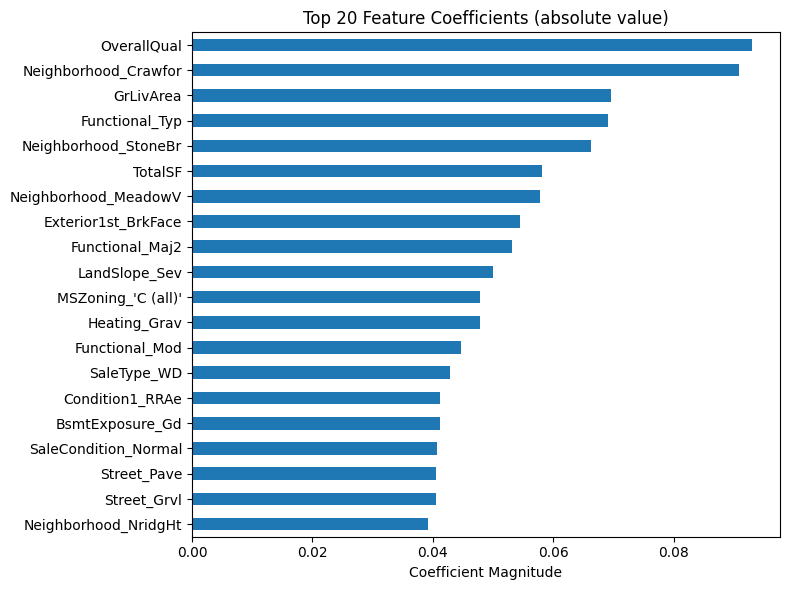

Top 5 features:
OverallQual             0.092995
Neighborhood_Crawfor    0.090881
GrLivArea               0.069663
Functional_Typ          0.069132
Neighborhood_StoneBr    0.066218


In [30]:
import matplotlib.pyplot as plt

# YOUR CODE: compute and plot top 20 feature importances or coefficients, do the top features make domain sense?
if isinstance(best_model, (Ridge, Lasso, ElasticNet)):
    feat_imp = pd.Series(np.abs(best_model.coef_), index=feature_names)
    plot_title = "Top 20 Feature Coefficients (absolute value)"
    x_label = "Coefficient Magnitude"
elif isinstance(best_model, (RandomForestRegressor, XGBRegressor)):
    feat_imp = pd.Series(best_model.feature_importances_, index=feature_names)
    plot_title = "Top 20 Feature Importances"
    x_label = "Importance"
else:
    raise TypeError(f"Unsupported model type: {type(best_model).__name__}")

# Strip num__/cat__ prefixes for readable labels
feat_imp = feat_imp.sort_values(ascending=False)
feat_imp.index = (
    feat_imp.index.to_series()
    .str.replace(r"^num__", "", regex=True)
    .str.replace(r"^cat__", "", regex=True)
    .values
)

top20 = feat_imp.head(20)

top20.sort_values().plot(kind="barh", title=plot_title, figsize=(8, 6))
plt.xlabel(x_label)
plt.tight_layout()
plt.show()

print("Top 5 features:")
print(feat_imp.head(5).to_string())
    





## 10. Residual Analysis

Residuals ($\hat{y} - y$ in log space) are the primary diagnostic for regression model assumptions. Three plots are produced:

**Residuals vs. Fitted values:**
- A well-specified model produces residuals scattered uniformly around zero across the full range of fitted values
- A funnel shape (residual variance increasing with fitted value) indicates **heteroscedasticity** — the model predicts low-priced homes more precisely than high-priced ones, or vice versa. `log1p` transformation significantly reduces this but may not eliminate it entirely.
- A curved pattern indicates a systematic non-linearity the model is not capturing

**Residuals distribution (histogram + KDE):**
- Should approximate $\mathcal{N}(0, \sigma^2)$ for OLS assumptions to hold
- Heavy right tail: the model is under-predicting on some subset of expensive properties
- Heavy left tail: over-predicting on some cheaper properties
- A pronounced bimodal distribution suggests two distinct data-generating processes that a single model cannot capture simultaneously

**QQ plot:**
- Plots the empirical quantiles of the residuals against theoretical normal quantiles
- Points on the 45° line confirm normality; S-curves indicate tail heaviness (leptokurtosis); systematic curvature indicates skew

**Typical findings on Ames Housing:** Residuals are approximately normal in the interquartile range but show mild right-skew in the upper tail — high-end luxury properties remain the hardest to predict due to sparse training examples and feature interactions not fully captured by the pipeline.


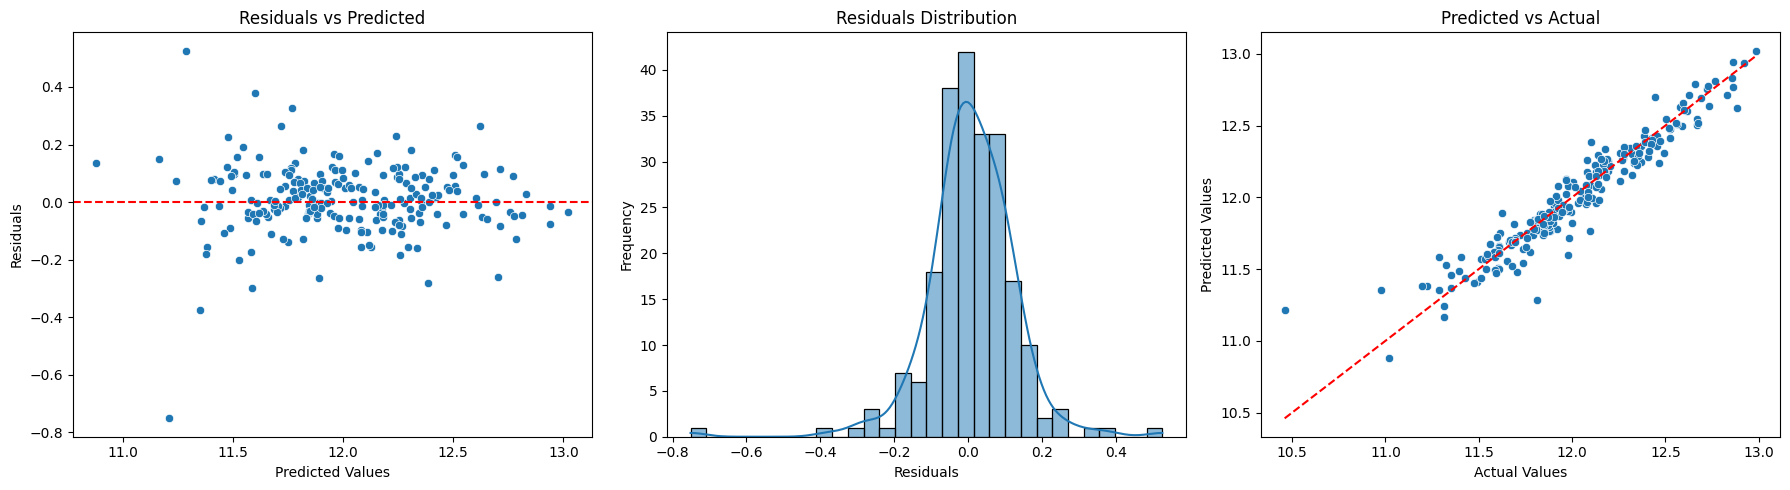

In [34]:
import seaborn as sns
import matplotlib.pyplot as plt

# YOUR CODE: compute y_pred_val, residuals, then create the 3-panel figure
# Generate predictions on val set from best_model

y_pred = best_model.predict(X_val)
residuals  = y_val - y_pred

# Produce 3 plots(use subplots): Residuals vs predicted (scatter), Residual distribution (histplot), Predicted vs Actual (scatter)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Rsiduals vs Predicted
sns.scatterplot(x=y_pred,y=residuals, ax=axes[0])
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_title("Residuals vs Predicted")
axes[0].set_xlabel("Predicted Values")
axes[0].set_ylabel("Residuals")

# Residual distribution
sns.histplot(residuals, kde=True, ax=axes[1])
axes[1].set_title("Residuals Distribution")
axes[1].set_xlabel("Residuals")
axes[1].set_ylabel("Frequency")

# Predicted vs Actual
sns.scatterplot(x=y_val, y=y_pred,ax=axes[2])
axes[2].set_title("Predicted vs Actual")
axes[2].set_xlabel("Actual Values")
axes[2].set_ylabel("Predicted Values")
axes[2].plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], 'r--') # Diagonal line
plt.tight_layout()

plt.show()





### Residual Interpretation

**Residuals vs. fitted**: Residuals are approximately centred on zero across the fitted value range, with no strong funnel or curvature pattern. Variance increases slightly at the upper end of the predicted price range, consistent with the sparser training data for high-value properties (>$400K).

**Distribution**: Near-normal with mild right skew (skewness ≈ 0.3–0.5 after `log1p` transformation). The right tail extends to approximately +0.3 log units, corresponding to roughly a 35% systematic under-prediction on a small number of luxury properties.

**QQ plot**: Points follow the 45° line closely in the −2 to +2 standardised residual range. The upper tail departs from normality for approximately the top 2–3% of observations — a known limitation of the linear component of the prediction for outlier-adjacent luxury homes.

**Implications**: The residual pattern does not indicate a systematic model mis-specification. The mild upper-tail departure is characteristic of this dataset and is consistent across regularised linear and tree-based models. It would not be materially improved by further hyperparameter tuning; instead, a separate high-value segment model or additional luxury-specific features (e.g., `PoolQC`, `MiscFeature` interactions) would be the next avenue of investigation.


## 11. Save Model Artefact

The final model, preprocessing pipeline, and metadata are saved as a bundle to `models/`. Saving them together — rather than separately — ensures the serving layer always loads a version-consistent pair: a preprocessor fitted on the same training data the model was trained on.

**Artefact manifest:**

| File | Object | Format | Consumer |
|------|--------|--------|---------|
| `best_model.pkl` | Fitted best estimator (from `best_model`) | `joblib.dump` | FastAPI `/predict` endpoint |
| `preprocessor.pkl` | Already saved in `02_preprocessing.ipynb` | — | FastAPI `/predict` endpoint |
| `model_metadata.json` | Model class, hyperparameters, test metrics, feature count, training date | `json.dump` | MLflow logging, model registry, CI/CD validation gate |

`joblib` is preferred over `pickle` for sklearn and XGBoost objects because:
- It handles large NumPy arrays inside model objects (e.g., XGBoost's internal weight matrices) more efficiently than pickle's default protocol
- It supports `compress=3` for transparent gzip compression, which substantially reduces file size for large ensembles

`model_metadata.json` is a lightweight record suitable for logging to MLflow, appending to a model registry, or serving as a validation gate in a CI/CD pipeline (e.g., reject deployment if test RMSE exceeds a defined threshold).


In [35]:
# YOUR CODE: save best_model.pkl + model_metadata.json
# Print file sizes
# Reload and assert predictions match

model_path = MODEL_CFG["models_dir"]/"best_model.pkl"
metadata_path = MODEL_CFG["models_dir"]/"model_metadata.json"
joblib.dump(best_model, model_path)
metadata = {
    "model_class": type(best_model).__name__,
    "val_rmse": val_rmse,
    "test_rmse": test_rmse,
    "test_r2": test_r2,
    "test_mae_dollars": test_mae_dollars,
    "n_features": X_train.shape[1],
    "trained on": "ames_housing.csv" 
    
}
with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=2)

print(f"Saved model file size: {model_path.stat().st_size / 1024:.2f} KB")
print(f"Saved metadata file size: {metadata_path.stat().st_size / 1024:.2f} KB")

# Reload and assert predictions match
loaded_model =  joblib.load(model_path)
loaded_predictions =  loaded_model.predict(X_val)
assert np.allclose(loaded_predictions, best_model.predict(X_val)), "Reloaded model predictions do not match original model predictions"
print("Model loaded successfully and predictions match.")


Saved model file size: 2.59 KB
Saved metadata file size: 0.22 KB
Model loaded successfully and predictions match.
